In [2]:

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find our project directory
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "ml" / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Make our custom Python modules importable
sys.path.insert(
    0,
    str(PROJECT_ROOT / "ml" / "src")
)

from aeroguard_ml.data_loader import (
    load_data,
    validate_data
)

# Configure visualizations
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

FIGURES_DIR = PROJECT_ROOT / "ml" / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("AeroGuard AI — EDA Environment Ready")
print("Project root:", PROJECT_ROOT)


AeroGuard AI — EDA Environment Ready
Project root: C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance


In [3]:

train_df, test_df, rul_df = load_data()

validate_data(train_df, test_df, rul_df)

print("\nTraining shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("RUL labels:", rul_df.shape)

display(train_df.head())



===== DATASET VALIDATION =====

Train Dataset
Shape: (20631, 26)
Unique engines: 100
Missing values: 0
Duplicate engine-cycle records: 0

Test Dataset
Shape: (13096, 26)
Unique engines: 100
Missing values: 0
Duplicate engine-cycle records: 0

RUL Dataset
Shape: (100, 1)
Missing values: 0

Basic validation completed successfully!

Training shape: (20631, 26)
Testing shape: (13096, 26)
RUL labels: (100, 1)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:

sensor_columns = [
    f"sensor_{i}" for i in range(1, 22)
]

sensor_stats = pd.DataFrame({
    "unique_values": train_df[sensor_columns].nunique(),
    "mean": train_df[sensor_columns].mean(),
    "std": train_df[sensor_columns].std(),
    "missing": train_df[sensor_columns].isna().sum()
})

display(sensor_stats.round(4))

constant_sensors = sensor_stats[
    sensor_stats["unique_values"] <= 1
].index.tolist()

print("\nConstant sensors:", constant_sensors)
print("Total constant sensors:", len(constant_sensors))


,unique_values,mean,std,missing
sensor_1,1,518.6700,0.0000,0
sensor_2,310,642.6809,0.5001,0
sensor_3,3012,1590.5231,6.1311,0
sensor_4,4051,1408.9338,9.0006,0
sensor_5,1,14.6200,0.0000,0
sensor_6,2,21.6098,0.0014,0
sensor_7,513,553.3677,0.8851,0
sensor_8,53,2388.0967,0.0710,0
sensor_9,6403,9065.2429,22.0829,0
sensor_10,1,1.3000,0.0000,0



Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Total constant sensors: 6


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: failure_cycle, dtype: float64


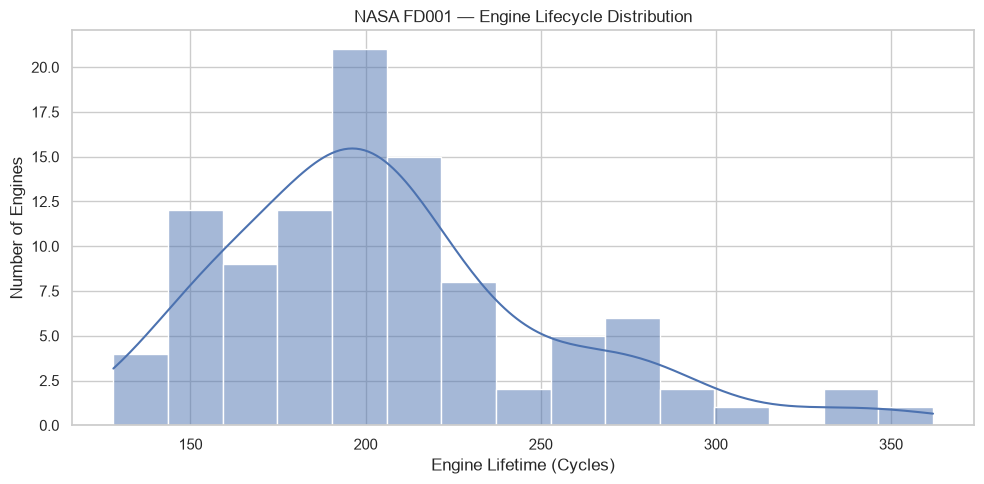

In [5]:

engine_lifetimes = (
    train_df.groupby("engine_id")["cycle"]
    .max()
    .reset_index(name="failure_cycle")
)

print(engine_lifetimes["failure_cycle"].describe())

# Save lifecycle statistics
engine_lifetimes.to_csv(
    PROJECT_ROOT / "ml" / "reports" / "engine_lifetimes.csv",
    index=False
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=engine_lifetimes,
    x="failure_cycle",
    bins=15,
    kde=True
)

plt.title("NASA FD001 — Engine Lifecycle Distribution")
plt.xlabel("Engine Lifetime (Cycles)")
plt.ylabel("Number of Engines")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "engine_lifecycle_distribution.png",
    dpi=180
)

plt.show()


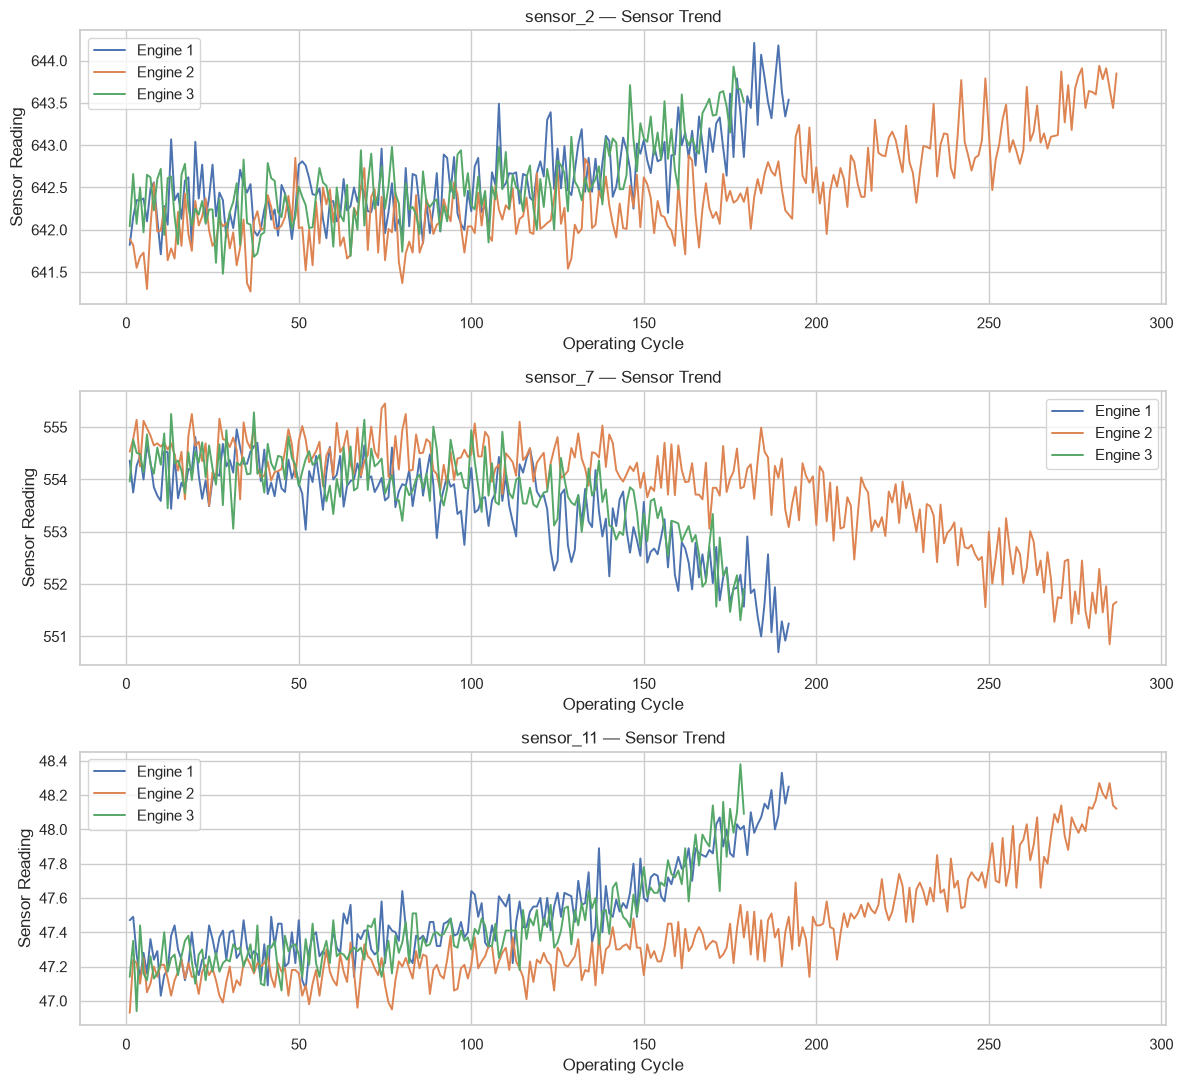

In [6]:

selected_engines = [1, 2, 3]
selected_sensors = [
    "sensor_2",
    "sensor_7",
    "sensor_11"
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 11)
)

for ax, sensor in zip(axes, selected_sensors):

    for engine_id in selected_engines:

        engine_data = train_df[
            train_df["engine_id"] == engine_id
        ]

        ax.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {engine_id}",
            linewidth=1.4
        )

    ax.set_title(f"{sensor} — Sensor Trend")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor Reading")
    ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_trends.png",
    dpi=180
)

plt.show()


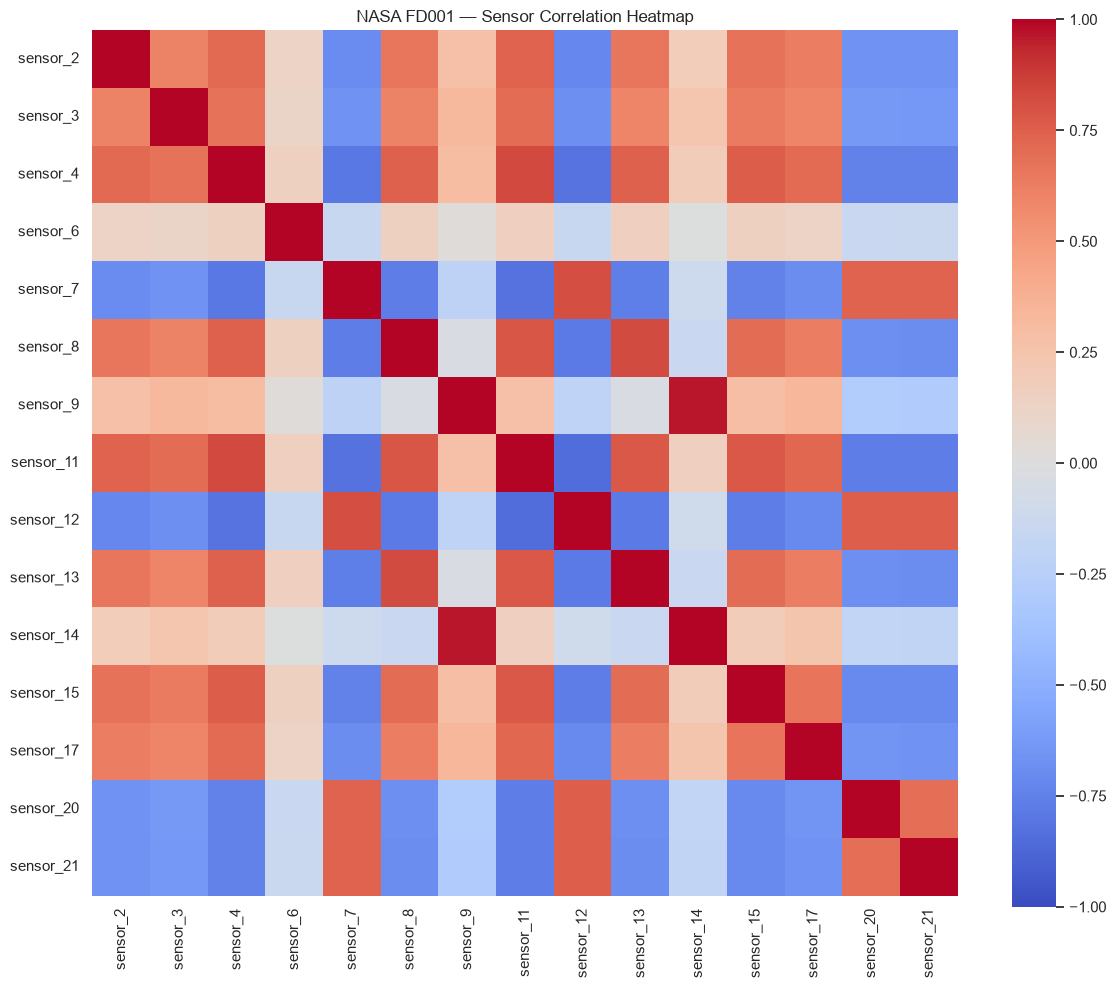

In [7]:

variable_sensors = [
    col for col in sensor_columns
    if train_df[col].nunique() > 1
]

correlation_matrix = train_df[
    variable_sensors
].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("NASA FD001 — Sensor Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_correlation_heatmap.png",
    dpi=180
)

plt.show()


In [8]:

# Step 10: Remaining Useful Life Calculation

# Work on a copy of the training data
train_rul_df = train_df.copy()

# Find the final operating cycle of each engine
max_cycles = train_rul_df.groupby(
    "engine_id"
)["cycle"].transform("max")

# Calculate RUL
train_rul_df["RUL"] = (
    max_cycles - train_rul_df["cycle"]
)

# Verify target labels
assert (train_rul_df["RUL"] >= 0).all()

final_rows = train_rul_df.loc[
    train_rul_df.groupby("engine_id")["cycle"].idxmax()
]

assert (final_rows["RUL"] == 0).all()

print("RUL labels generated successfully!")

display(
    train_rul_df[
        ["engine_id", "cycle", "RUL"]
    ].head(10)
)

print("\nRUL Statistics:")
print(train_rul_df["RUL"].describe())

# Save processed dataset
output_path = (
    PROJECT_ROOT /
    "data/processed/train_FD001_with_RUL.csv"
)

train_rul_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)


RUL labels generated successfully!


,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182



RUL Statistics:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

Saved to: C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\data\processed\train_FD001_with_RUL.csv


In [9]:

# Step 11: Leakage-Free Train/Validation Split

from sklearn.model_selection import GroupShuffleSplit

# Dataset with RUL targets from Step 10
df = train_rul_df.copy()

# Create grouped splitting strategy
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Split by engine ID
train_idx, val_idx = next(
    splitter.split(
        df,
        groups=df["engine_id"]
    )
)

# Create separate datasets
train_data = df.iloc[train_idx].copy()
val_data = df.iloc[val_idx].copy()

# Identify engines in each dataset
train_engines = set(train_data["engine_id"])
val_engines = set(val_data["engine_id"])

print("===== TRAIN / VALIDATION SPLIT =====")

print("Training shape:", train_data.shape)
print("Validation shape:", val_data.shape)

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

# Leakage checks
assert train_engines.isdisjoint(val_engines), (
    "Data leakage: engine overlap detected!"
)

assert len(train_data) + len(val_data) == len(df)

assert len(train_engines) == 80
assert len(val_engines) == 20

print("\nNo engine overlap detected!")
print("Train/validation split successful!")

# Save processed datasets
processed_dir = PROJECT_ROOT / "data" / "processed"

train_data.to_csv(
    processed_dir / "train_split.csv",
    index=False
)

val_data.to_csv(
    processed_dir / "validation_split.csv",
    index=False
)

print("\nProcessed splits saved successfully!")


===== TRAIN / VALIDATION SPLIT =====
Training shape: (16561, 27)
Validation shape: (4070, 27)
Training engines: 80
Validation engines: 20

No engine overlap detected!
Train/validation split successful!

Processed splits saved successfully!


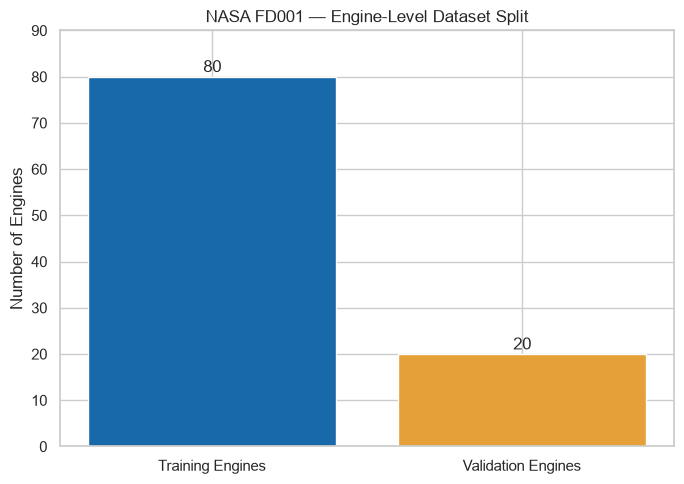

In [10]:

import matplotlib.pyplot as plt

labels = ["Training Engines", "Validation Engines"]
values = [len(train_engines), len(val_engines)]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    values,
    color=["#1769AA", "#E5A039"]
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha="center",
        fontsize=12
    )

plt.title("NASA FD001 — Engine-Level Dataset Split")
plt.ylabel("Number of Engines")
plt.ylim(0, 90)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "train_validation_split.png",
    dpi=180
)

plt.show()


In [11]:

from aeroguard_ml.feature_engineering import engineer_features

# Original candidate inputs
sensor_columns = [
    f"sensor_{i}" for i in range(1, 22)
]

candidate_inputs = (
    ["cycle", "setting_1", "setting_2", "setting_3"]
    + sensor_columns
)

# Identify constant features using TRAINING engines only
active_inputs = [
    col for col in candidate_inputs
    if train_data[col].nunique() > 1
]

removed_features = [
    col for col in candidate_inputs
    if col not in active_inputs
]

# Sensors selected for historical feature engineering
active_sensors = [
    col for col in sensor_columns
    if col in active_inputs
]

print("Removed constant features:", removed_features)
print("Active sensors:", len(active_sensors))

# Engineer training features
train_features = engineer_features(
    train_data, active_sensors
)

# Engineer validation features independently
val_features = engineer_features(
    val_data, active_sensors
)

# Collect only our model input features
engineered_columns = [
    col for col in train_features.columns
    if col not in train_data.columns
]

feature_columns = active_inputs + engineered_columns

# Create feature matrices and target vectors
X_train = train_features[feature_columns]
y_train = train_features["RUL"]

X_val = val_features[feature_columns]
y_val = val_features["RUL"]

print("\n===== FEATURE ENGINEERING =====")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Total model features:", len(feature_columns))

# Important checks
assert "RUL" not in feature_columns
assert "engine_id" not in feature_columns
assert X_train.columns.tolist() == X_val.columns.tolist()

assert not X_train.isna().any().any()
assert not X_val.isna().any().any()

assert set(train_features["engine_id"]).isdisjoint(
    set(val_features["engine_id"])
)

print("\nFeature engineering successful!")
print("No missing values or engine overlap detected.")


Removed constant features: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Active sensors: 15


C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\ml\src\aeroguard_ml\feature_engineering.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result[f"{sensor}_mean_{window}"] = (
C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\ml\src\aeroguard_ml\feature_engineering.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result[f"{sensor}_std_{window}"] = (
C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\ml\src\aeroguard_ml\feature_engineering.py:50: PerformanceWarning: DataFram


===== FEATURE ENGINEERING =====
Training shape: (16561, 123)
Validation shape: (4070, 123)
Total model features: 123

Feature engineering successful!
No missing values or engine overlap detected.


In [12]:

# Select one training engine
sample_engine = sorted(train_engines)[0]

engine_history = train_data[
    train_data["engine_id"] == sample_engine
].sort_values("cycle")

# Features from the complete observed history
full_features = engineer_features(
    engine_history, active_sensors
)

# Features from only the first 40 cycles
partial_features = engineer_features(
    engine_history.head(40),
    active_sensors
)

# First 40 feature rows must match
pd.testing.assert_frame_equal(
    full_features[feature_columns]
    .head(40)
    .reset_index(drop=True),

    partial_features[feature_columns]
    .reset_index(drop=True)
)

print("Passed: Features do not depend on future cycles.")


C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\ml\src\aeroguard_ml\feature_engineering.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result[f"{sensor}_mean_{window}"] = (
C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\ml\src\aeroguard_ml\feature_engineering.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result[f"{sensor}_std_{window}"] = (
C:\Users\EHAAB ULLAH\Projects\AeroGuard-AI-Predictive-Maintenance\ml\src\aeroguard_ml\feature_engineering.py:50: PerformanceWarning: DataFram

Passed: Features do not depend on future cycles.


In [13]:

# Save the complete engineered datasets
processed_dir = PROJECT_ROOT / "data" / "processed"

train_features.to_csv(
    processed_dir / "train_engineered.csv",
    index=False
)

val_features.to_csv(
    processed_dir / "validation_engineered.csv",
    index=False
)

# Record our chosen feature names
feature_report = PROJECT_ROOT / "docs" / "feature-columns.txt"

feature_report.write_text(
    "\n".join(feature_columns),
    encoding="utf-8"
)

print("Engineered datasets saved!")
print("Feature specification saved!")


Engineered datasets saved!
Feature specification saved!
